# Random Forest / Regressor

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** `15-gym_crowdedness.csv`.  
**Methods referenced:** `LinearRegression`, `Ridge`, `Lasso`, `DecisionTreeRegressor`, `RandomForestRegressor`, `KNeighborsRegressor`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression,Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
df = pd.read_csv("15-gym_crowdedness.csv")

In [3]:
df.head(10)

,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
0,37,2015-08-14 17:00:11-07:00,61211,4,0,0,71.76,0,0,8,17
1,45,2015-08-14 17:20:14-07:00,62414,4,0,0,71.76,0,0,8,17
2,40,2015-08-14 17:30:15-07:00,63015,4,0,0,71.76,0,0,8,17
3,44,2015-08-14 17:40:16-07:00,63616,4,0,0,71.76,0,0,8,17
4,45,2015-08-14 17:50:17-07:00,64217,4,0,0,71.76,0,0,8,17
5,46,2015-08-14 18:00:18-07:00,64818,4,0,0,72.15,0,0,8,18
6,43,2015-08-14 18:20:08-07:00,66008,4,0,0,72.15,0,0,8,18
7,53,2015-08-14 18:30:09-07:00,66609,4,0,0,72.15,0,0,8,18
8,54,2015-08-14 18:40:14-07:00,67214,4,0,0,72.15,0,0,8,18
9,43,2015-08-14 18:50:15-07:00,67815,4,0,0,72.15,0,0,8,18


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62184 entries, 0 to 62183
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   number_people         62184 non-null  int64  
 1   date                  62184 non-null  object 
 2   timestamp             62184 non-null  int64  
 3   day_of_week           62184 non-null  int64  
 4   is_weekend            62184 non-null  int64  
 5   is_holiday            62184 non-null  int64  
 6   temperature           62184 non-null  float64
 7   is_start_of_semester  62184 non-null  int64  
 8   is_during_semester    62184 non-null  int64  
 9   month                 62184 non-null  int64  
 10  hour                  62184 non-null  int64  
dtypes: float64(1), int64(9), object(1)
memory usage: 5.2+ MB


In [5]:
df.isna().sum()

number_people           0
date                    0
timestamp               0
day_of_week             0
is_weekend              0
is_holiday              0
temperature             0
is_start_of_semester    0
is_during_semester      0
month                   0
hour                    0
dtype: int64

In [6]:
df.describe()

,number_people,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
count,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000,62184.000000
mean,29.072543,45799.437958,2.982504,0.282870,0.002573,58.557108,0.078831,0.660218,7.439824,12.236460
std,22.689026,24211.275891,1.996825,0.450398,0.050660,6.316396,0.269476,0.473639,3.445069,6.717631
min,0.000000,0.000000,0.000000,0.000000,0.000000,38.140000,0.000000,0.000000,1.000000,0.000000
25%,9.000000,26624.000000,1.000000,0.000000,0.000000,55.000000,0.000000,0.000000,5.000000,7.000000
50%,28.000000,46522.500000,3.000000,0.000000,0.000000,58.340000,0.000000,1.000000,8.000000,12.000000
75%,43.000000,66612.000000,5.000000,1.000000,0.000000,62.280000,0.000000,1.000000,10.000000,18.000000
max,145.000000,86399.000000,6.000000,1.000000,1.000000,87.170000,1.000000,1.000000,12.000000,23.000000


In [7]:
df["date"] = pd.to_datetime(df["date"], utc = True)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62184 entries, 0 to 62183
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype              
---  ------                --------------  -----              
 0   number_people         62184 non-null  int64              
 1   date                  62184 non-null  datetime64[ns, UTC]
 2   timestamp             62184 non-null  int64              
 3   day_of_week           62184 non-null  int64              
 4   is_weekend            62184 non-null  int64              
 5   is_holiday            62184 non-null  int64              
 6   temperature           62184 non-null  float64            
 7   is_start_of_semester  62184 non-null  int64              
 8   is_during_semester    62184 non-null  int64              
 9   month                 62184 non-null  int64              
 10  hour                  62184 non-null  int64              
dtypes: datetime64[ns, UTC](1), float64(1), int64(9)
memory usage: 5.2 M

In [9]:
df.head(10)

,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
0,37,2015-08-15 00:00:11+00:00,61211,4,0,0,71.76,0,0,8,17
1,45,2015-08-15 00:20:14+00:00,62414,4,0,0,71.76,0,0,8,17
2,40,2015-08-15 00:30:15+00:00,63015,4,0,0,71.76,0,0,8,17
3,44,2015-08-15 00:40:16+00:00,63616,4,0,0,71.76,0,0,8,17
4,45,2015-08-15 00:50:17+00:00,64217,4,0,0,71.76,0,0,8,17
5,46,2015-08-15 01:00:18+00:00,64818,4,0,0,72.15,0,0,8,18
6,43,2015-08-15 01:20:08+00:00,66008,4,0,0,72.15,0,0,8,18
7,53,2015-08-15 01:30:09+00:00,66609,4,0,0,72.15,0,0,8,18
8,54,2015-08-15 01:40:14+00:00,67214,4,0,0,72.15,0,0,8,18
9,43,2015-08-15 01:50:15+00:00,67815,4,0,0,72.15,0,0,8,18


In [10]:
df["year"] = df["date"].dt.year

In [11]:
df.head(10)

,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour,year
0,37,2015-08-15 00:00:11+00:00,61211,4,0,0,71.76,0,0,8,17,2015
1,45,2015-08-15 00:20:14+00:00,62414,4,0,0,71.76,0,0,8,17,2015
2,40,2015-08-15 00:30:15+00:00,63015,4,0,0,71.76,0,0,8,17,2015
3,44,2015-08-15 00:40:16+00:00,63616,4,0,0,71.76,0,0,8,17,2015
4,45,2015-08-15 00:50:17+00:00,64217,4,0,0,71.76,0,0,8,17,2015
5,46,2015-08-15 01:00:18+00:00,64818,4,0,0,72.15,0,0,8,18,2015
6,43,2015-08-15 01:20:08+00:00,66008,4,0,0,72.15,0,0,8,18,2015
7,53,2015-08-15 01:30:09+00:00,66609,4,0,0,72.15,0,0,8,18,2015
8,54,2015-08-15 01:40:14+00:00,67214,4,0,0,72.15,0,0,8,18,2015
9,43,2015-08-15 01:50:15+00:00,67815,4,0,0,72.15,0,0,8,18,2015


In [12]:
df.drop("date", axis = 1, inplace = True)

In [13]:
df.head(10)

,number_people,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour,year
0,37,61211,4,0,0,71.76,0,0,8,17,2015
1,45,62414,4,0,0,71.76,0,0,8,17,2015
2,40,63015,4,0,0,71.76,0,0,8,17,2015
3,44,63616,4,0,0,71.76,0,0,8,17,2015
4,45,64217,4,0,0,71.76,0,0,8,17,2015
5,46,64818,4,0,0,72.15,0,0,8,18,2015
6,43,66008,4,0,0,72.15,0,0,8,18,2015
7,53,66609,4,0,0,72.15,0,0,8,18,2015
8,54,67214,4,0,0,72.15,0,0,8,18,2015
9,43,67815,4,0,0,72.15,0,0,8,18,2015


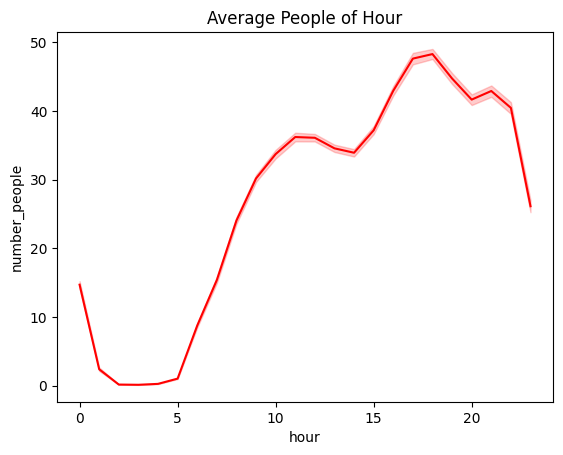

In [14]:
sns.lineplot(data = df, x = "hour", y = "number_people", color = "r")
plt.title("Average People of Hour")
plt.show()

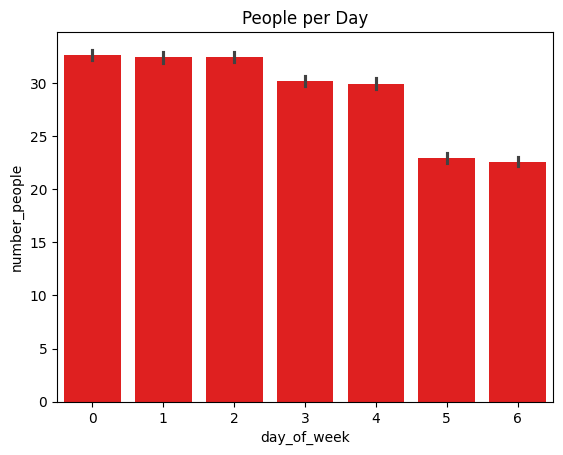

In [15]:
sns.barplot(data = df, x = "day_of_week", y="number_people", color = "r")
plt.title("People per Day")
plt.show()

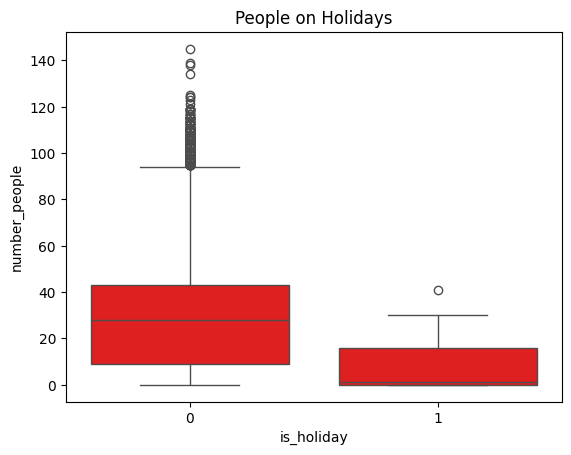

In [16]:
sns.boxplot(data=df, x="is_holiday", y="number_people", color="r")
plt.title("People on Holidays")
plt.show()

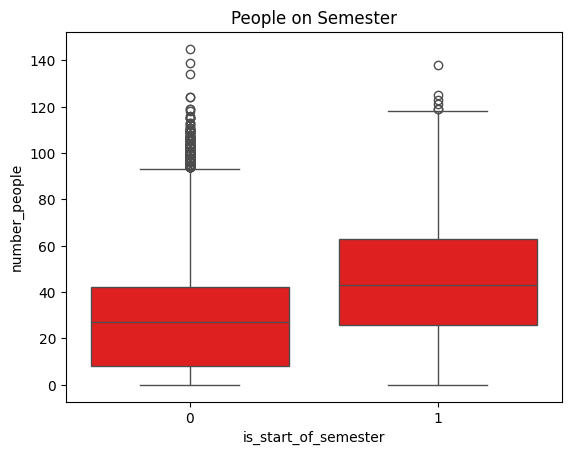

In [17]:
sns.boxplot(data=df, x="is_start_of_semester", y="number_people", color="r")
plt.title("People on Semester")
plt.show()

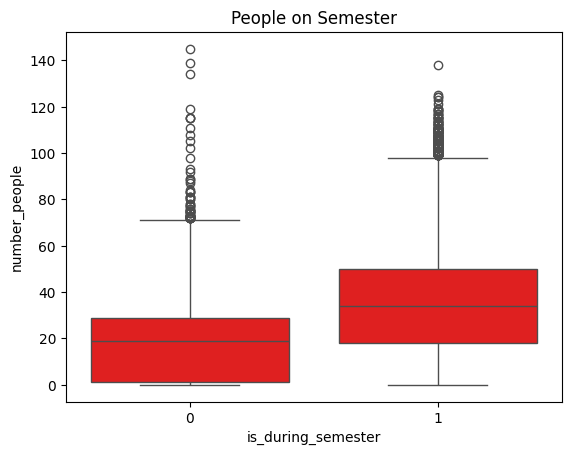

In [18]:
sns.boxplot(data=df, x="is_during_semester", y="number_people", color="r")
plt.title("People on Semester")
plt.show()

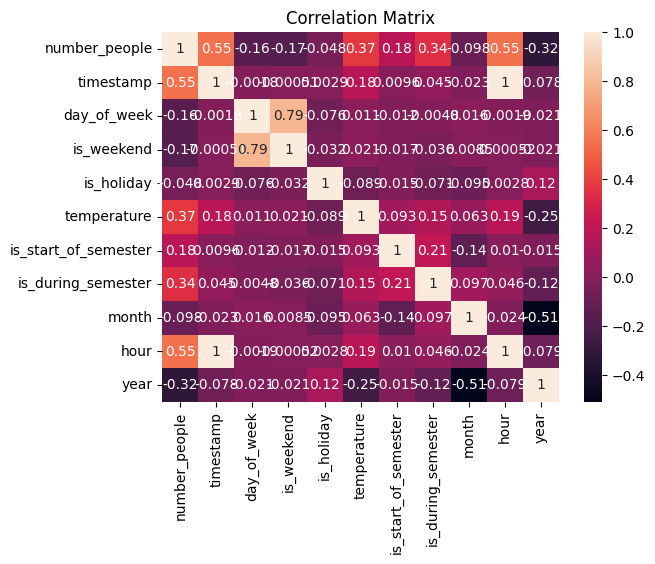

In [19]:
sns.heatmap(data=df.corr(numeric_only=True), annot=True)
plt.title("Correlation Matrix")
plt.show()

In [20]:
df.head(10)

,number_people,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour,year
0,37,61211,4,0,0,71.76,0,0,8,17,2015
1,45,62414,4,0,0,71.76,0,0,8,17,2015
2,40,63015,4,0,0,71.76,0,0,8,17,2015
3,44,63616,4,0,0,71.76,0,0,8,17,2015
4,45,64217,4,0,0,71.76,0,0,8,17,2015
5,46,64818,4,0,0,72.15,0,0,8,18,2015
6,43,66008,4,0,0,72.15,0,0,8,18,2015
7,53,66609,4,0,0,72.15,0,0,8,18,2015
8,54,67214,4,0,0,72.15,0,0,8,18,2015
9,43,67815,4,0,0,72.15,0,0,8,18,2015


In [21]:
df.drop("timestamp", axis = 1, inplace = True)

In [22]:
X = df.drop("number_people", axis = 1)
y = df["number_people"]

In [23]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

In [24]:
from sklearn.preprocessing import StandardScaler

In [25]:
scaler = StandardScaler()

In [26]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [27]:
def calculate_model_metrics(test, predict):
    mae = mean_absolute_error(test, predict)
    mse = mean_squared_error(test, predict)
    rmse = np.sqrt(mean_squared_error(test, predict))
    r2_square = r2_score(test, predict)
    return mae, rmse, r2_square

In [28]:
models = {
    "Linear Regression": LinearRegression(),
    "Lasso": Lasso(),
    "Ridge": Ridge(),
    "KNighbors Regressor": KNeighborsRegressor(),
    "Decision Tree Regressor": DecisionTreeRegressor(),
    "Random Forest Regressor": RandomForestRegressor()
}

In [29]:
for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)

    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)

    model_train_mae, model_train_rmse, model_train_r2 = calculate_model_metrics(y_train, y_train_pred)
    model_test_mae, model_test_rmse, model_test_r2 = calculate_model_metrics(y_test, y_test_pred)

    print(list(models.values())[i])

    print("Evaluation for Training Set")
    print("RMSE :", model_train_rmse)
    print("Mean Absolute Error :", model_train_mae)
    print("R2 Score :", model_train_r2)

    print("-----------------------------")
    
    print("Evaluation for Test Set")
    print("RMSE :", model_test_rmse)
    print("Mean Absolute Error :", model_test_mae)
    print("R2 Score :", model_test_r2)

    print("-----------------------------")
    print("\n")

LinearRegression()
Evaluation for Training Set
RMSE : 14.380902408521694
Mean Absolute Error : 10.766486863133512
R2 Score : 0.5954782069008537
-----------------------------
Evaluation for Test Set
RMSE : 14.294674005122268
Mean Absolute Error : 10.701786597583666
R2 Score : 0.6093135231288089
-----------------------------


Lasso()
Evaluation for Training Set
RMSE : 14.625711594498869
Mean Absolute Error : 10.971961776035206
R2 Score : 0.5815884581151352
-----------------------------
Evaluation for Test Set
RMSE : 14.573271098862026
Mean Absolute Error : 10.929324618424227
R2 Score : 0.5939364981379507
-----------------------------


Ridge()
Evaluation for Training Set
RMSE : 14.380902414971917
Mean Absolute Error : 10.766496480578326
R2 Score : 0.5954782065379758
-----------------------------
Evaluation for Test Set
RMSE : 14.294677674542434
Mean Absolute Error : 10.701798174730014
R2 Score : 0.6093133225515841
-----------------------------


KNeighborsRegressor()
Evaluation for Trai